# Electrode impedance over time — effect of the smoothing window

**Entry point** for the `impedance` task. The notebook reads every anonymized
impedance recording in `datafiles/impedance/` (pattern
`task_name-session-VR_set-device.csv` + JSON sidecar), groups recordings by
*task × session × device*, and within each group compares the VR conditions
(no VR, HTC, Meta Quest).

It produces, per group:

1. per-recording figures of impedance vs. time smoothed with several window lengths;
2. a condition-overlay figure (all VR sets on one time axis, per channel);
3. a window-sensitivity figure (how much short-term variation each window removes);
4. summary tables (CSV + LaTeX) and a TeX macro file used by the article in
   `outputs/impedance/article/`.

Everything is written to `outputs/impedance/`. Works for any EEG channel count
(8/16/32): channels are taken from the sidecar (`type == "EEG"`).

## Parameters

* `WINDOWS_S` — rolling-median window lengths (seconds) compared throughout.
* `REFERENCE_WINDOW_S` — the window used for the condition-overlay figure and
  for the settling-time estimate.
* `EDGE_S` — length of the start/end segments used for "initial" and "final" impedance.
* `SETTLE_TOL`, `SETTLE_ABS` — settling band around the final impedance: ±max(`SETTLE_TOL`·final, `SETTLE_ABS`).
  The absolute floor stops integer quantisation of low impedances (e.g. 14 vs 17 kΩ) from counting as unsettled.
* `CONDITION_ORDER` — display order of VR sets (unknown VR sets are appended).

In [1]:
from pathlib import Path
import datetime as dt
import json, re, platform

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "datafiles").is_dir():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError("Could not locate project root (folder containing datafiles/)")
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "datafiles" / "impedance"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "impedance"
FILE_GLOB = "*.csv"

WINDOWS_S = [1, 5, 15, 30]
REFERENCE_WINDOW_S = 5
EDGE_S = 10
SETTLE_TOL = 0.10
SETTLE_ABS = 10      # minimum half-width of the settling band, in the impedance unit (kOhm)
CONDITION_ORDER = ["NoVR", "HTC", "MetaQuest"]

In [2]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, FuncFormatter, NullFormatter, MultipleLocator
from scipy import stats

NOTEBOOK = "processing/impedance/impedance_over_time.ipynb"
RUN_DATE = dt.date.today().isoformat()
assert REFERENCE_WINDOW_S in WINDOWS_S, "REFERENCE_WINDOW_S must be one of WINDOWS_S"

print(f"Notebook        : {NOTEBOOK}")
print(f"Processing date : {RUN_DATE}")
print(f"Data dir        : {DATA_DIR.relative_to(PROJECT_ROOT)}")
print(f"Output dir      : {OUTPUT_DIR.relative_to(PROJECT_ROOT)}")
print(f"Windows (s)     : {WINDOWS_S}  (reference {REFERENCE_WINDOW_S} s)")
print(f"Edge segment    : {EDGE_S} s, settling band ±max({SETTLE_TOL:.0%}, {SETTLE_ABS} kOhm)")
print(f"Python {platform.python_version()}, numpy {np.__version__}, pandas {pd.__version__}, "
      f"scipy {stats.__name__ and __import__('scipy').__version__}, matplotlib {matplotlib.__version__}")

Notebook        : processing/impedance/impedance_over_time.ipynb
Processing date : 2026-11-06
Data dir        : datafiles/impedance
Output dir      : outputs/impedance
Windows (s)     : [1, 5, 15, 30]  (reference 5 s)
Edge segment    : 10 s, settling band ±max(10%, 10 kOhm)
Python 3.14.8, numpy 2.5.4, pandas 3.0.6, scipy 1.18.1, matplotlib 3.11.2


## Loading and validation

For every CSV the notebook checks, and stops with an error otherwise:

* the filename matches `task-session-VR_set-device.csv` and agrees with the sidecar;
* the sidecar exists, the sampling frequency is positive and the device sample counter was gap-free at conversion;
* all EEG channels listed in the sidecar, `time_s` and `Sample` are present; the
  number of EEG channels equals the sidecar's `n_eeg_channels`;
* no missing values; `Sample` increments by exactly 1 and `time_s == Sample / fs`.

No values are substituted or interpolated. The EEG columns of an impedance
recording hold electrode impedance in kΩ (unit taken from the sidecar).
**No samples are excluded**: the `Streaming` column is a periodic 3-sample
pulse every 2.4 s, not a start/stop flag, so it is not used for exclusion.

In [3]:
NAME_RE = re.compile(r"^(?P<task>[^-]+)-(?P<session>[^-]+)-(?P<vr_set>[^-]+)-(?P<device>[^-]+)\.csv$")

def load_recording(csv_path: Path) -> dict:
    m = NAME_RE.match(csv_path.name)
    if not m:
        raise ValueError(f"{csv_path.name}: filename does not match task-session-VR_set-device.csv")
    meta_path = csv_path.with_suffix(".json")
    if not meta_path.exists():
        raise FileNotFoundError(f"{csv_path.name}: sidecar {meta_path.name} missing")
    meta = json.loads(meta_path.read_text())
    for key in ("task", "session", "vr_set", "device"):
        if meta[key] != m[key]:
            raise ValueError(f"{csv_path.name}: filename {key}={m[key]!r} != sidecar {meta[key]!r}")
    fs = float(meta["sampling_frequency_hz"])
    if fs <= 0:
        raise ValueError(f"{csv_path.name}: invalid sampling frequency {fs}")
    if not meta.get("sample_counter_continuous", False):
        raise ValueError(f"{csv_path.name}: sample counter not continuous at conversion")
    eeg = [c for c, v in meta["channels"].items() if v["type"] == "EEG"]
    if len(eeg) != meta["n_eeg_channels"]:
        raise ValueError(f"{csv_path.name}: {len(eeg)} EEG channels in sidecar, expected {meta['n_eeg_channels']}")
    units = {meta["channels"][c]["unit"] for c in eeg}
    if len(units) != 1:
        raise ValueError(f"{csv_path.name}: mixed EEG units {units}")

    df = pd.read_csv(csv_path)
    missing = [c for c in ["time_s", "Sample", *eeg] if c not in df.columns]
    if missing:
        raise ValueError(f"{csv_path.name}: missing columns {missing}")
    if len(df) != meta["n_samples"]:
        raise ValueError(f"{csv_path.name}: {len(df)} rows, sidecar says {meta['n_samples']}")
    na = df[["time_s", "Sample", *eeg]].isna().sum()
    if na.any():
        raise ValueError(f"{csv_path.name}: missing values {na[na > 0].to_dict()}")
    if not (np.diff(df["Sample"].to_numpy()) == 1).all():
        raise ValueError(f"{csv_path.name}: Sample counter has gaps")
    if not np.allclose(df["time_s"].to_numpy(), df["Sample"].to_numpy() / fs, atol=1e-6):
        raise ValueError(f"{csv_path.name}: time_s inconsistent with Sample / fs")
    return dict(path=csv_path, meta=meta, fs=fs, eeg=eeg, unit=units.pop(),
                time=df["time_s"].to_numpy(), z=df[eeg].astype(float))

files = sorted(DATA_DIR.glob(FILE_GLOB))
if not files:
    raise FileNotFoundError(f"No files matching {FILE_GLOB} in {DATA_DIR}")
recordings = [load_recording(p) for p in files]

groups = {}
for r in recordings:
    m = r["meta"]
    groups.setdefault((m["task"], m["session"], m["device"]), []).append(r)
for key, recs in groups.items():
    order = {c: i for i, c in enumerate(CONDITION_ORDER)}
    recs.sort(key=lambda r: (order.get(r["meta"]["vr_set"], len(order)), r["meta"]["vr_set"]))
    vrs = [r["meta"]["vr_set"] for r in recs]
    if len(set(vrs)) != len(vrs):
        raise ValueError(f"Group {key}: duplicate VR set {vrs}")
    if len({tuple(r["eeg"]) for r in recs}) != 1:
        raise ValueError(f"Group {key}: EEG channel sets differ between recordings")

inventory = pd.DataFrame([{
    "file": r["path"].name, "task": r["meta"]["task"], "session": r["meta"]["session"],
    "vr_set": r["meta"]["vr_set"], "device": r["meta"]["device"], "subject": r["meta"]["subject"],
    "n_eeg_channels": len(r["eeg"]), "fs_hz": r["fs"], "n_samples": len(r["time"]),
    "duration_s": round(len(r["time"]) / r["fs"], 3), "unit": r["unit"],
} for r in recordings])
inventory

,file,task,session,vr_set,device,subject,n_eeg_channels,fs_hz,n_samples,duration_s,unit
0,impedance-S001-HTC-BA_MINI_8ch.csv,impedance,S001,HTC,BA_MINI_8ch,sub-1,8,250.0,39000,156.000,kOhm
1,impedance-S001-MetaQuest-BA_MINI_8ch.csv,impedance,S001,MetaQuest,BA_MINI_8ch,sub-1,8,250.0,42000,168.000,kOhm
2,impedance-S001-NoVR-BA_MINI_8ch.csv,impedance,S001,NoVR,BA_MINI_8ch,sub-1,8,250.0,38406,153.624,kOhm


## Smoothing with windows of different length

Impedance is reported by the device as a step-wise signal (values are held
between impedance updates) with occasional short spikes of several thousand kΩ.
Each channel is therefore smoothed with a **centred rolling median** — robust
to spikes — of length *w* ∈ `WINDOWS_S`. At the start and end of a recording
the window is truncated; a value is reported only when at least half of the
window is available (`min_periods = w·fs/2`), so the first and last *w*/2
seconds of each smoothed trace are missing rather than extrapolated.

Window length trades responsiveness for stability: short windows follow
transient changes (and spikes), long windows show the slow drift.

In [4]:
def rolling_median(z: pd.DataFrame, fs: float, window_s: float) -> pd.DataFrame:
    n = int(round(window_s * fs))
    return z.rolling(n, center=True, min_periods=max(1, n // 2)).median()

smoothed = {}   # (task, session, device, vr_set, window_s) -> DataFrame
for key, recs in groups.items():
    for r in recs:
        for w in WINDOWS_S:
            smoothed[(*key, r["meta"]["vr_set"], w)] = rolling_median(r["z"], r["fs"], w)
print(f"{len(smoothed)} smoothed traces ({len(recordings)} recordings x {len(WINDOWS_S)} windows)")

12 smoothed traces (3 recordings x 4 windows)


### Figure style

Static publication figures. Colours: VR conditions use the first three slots
of a validated categorical palette (blue / orange / aqua — colour-vision-deficiency
safe for all pairs); window lengths use a single-hue blue ramp, light = short
window, dark = long window. Every multi-series figure has a legend. Impedance
spans more than two orders of magnitude, so the y-axis is logarithmic.

In [5]:
COND_COLORS = {"NoVR": "#2a78d6", "HTC": "#eb6834", "MetaQuest": "#1baf7a"}
COND_LABELS = {"NoVR": "No VR", "HTC": "HTC Vive", "MetaQuest": "Meta Quest"}
WINDOW_RAMP = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
RAW_COLOR = "#c3c2b7"
INK, INK2 = "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 8.5,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "axes.titlesize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "xtick.color": INK2, "ytick.color": INK2, "legend.frameon": False,
    "lines.linewidth": 1.4, "pdf.fonttype": 42,
})

def cond_color(vr):  # unknown VR sets fall back to neutral ink, never a generated hue
    return COND_COLORS.get(vr, INK2)

def log_axis(ax):
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.xaxis.set_major_locator(MultipleLocator(60))

def channel_grid(n_ch, height_per_row=1.55):
    ncols = 4
    nrows = int(np.ceil(n_ch / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(7.2, height_per_row * nrows + 0.9),
                             sharex=True, sharey=True, squeeze=False)
    flat = list(axes.flat)
    for ax in flat[n_ch:]:
        ax.set_visible(False)
    return fig, flat[:n_ch]

def label_axes(axes, ylabel, ncols=4):
    n = len(axes)
    for i, ax in enumerate(axes):
        if i + ncols >= n:  # bottom visible panel of each column
            ax.set_xlabel("time (s)")
            ax.tick_params(labelbottom=True)
        if i % ncols == 0:
            ax.set_ylabel(ylabel)

def stem(task, session, device, vr=None):
    return f"{task}-{session}-{vr}-{device}" if vr else f"{task}-{session}-{device}"

FIG_DIR, TAB_DIR = OUTPUT_DIR / "figures", OUTPUT_DIR / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True); TAB_DIR.mkdir(parents=True, exist_ok=True)
generated = []

def save(fig, name):
    for ext in ("pdf", "png"):
        p = FIG_DIR / f"{name}.{ext}"
        fig.savefig(p, bbox_inches="tight", metadata={"Creator": NOTEBOOK} if ext == "pdf" else None)
        generated.append(p)

### Figure A — one recording, all window lengths

Raw impedance in light grey, rolling medians from the shortest (light) to the
longest (dark) window. One figure per recording.

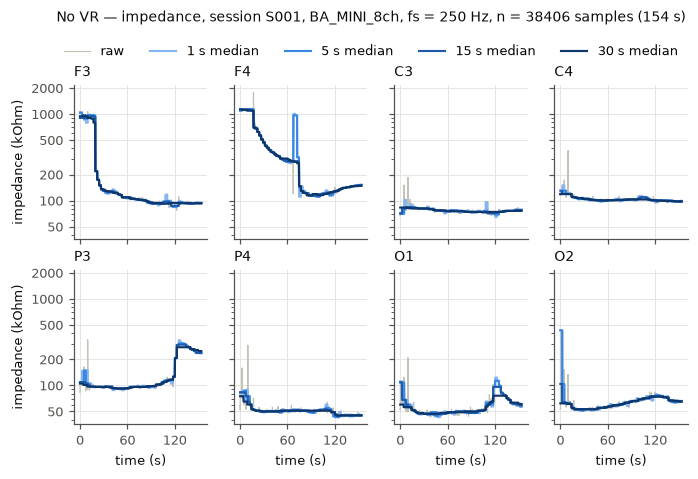

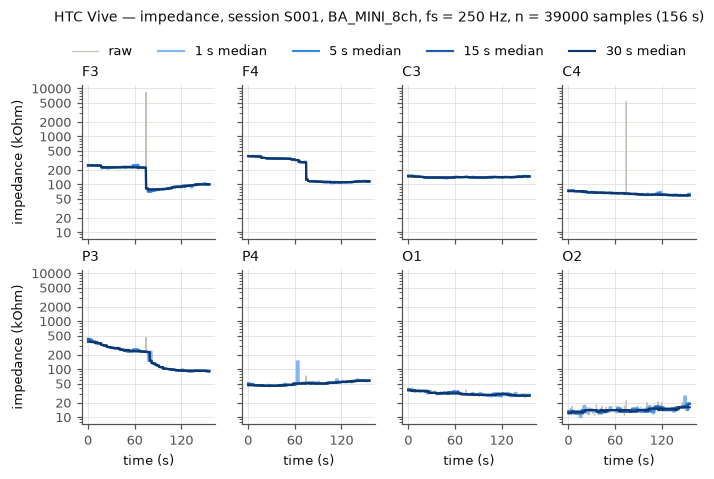

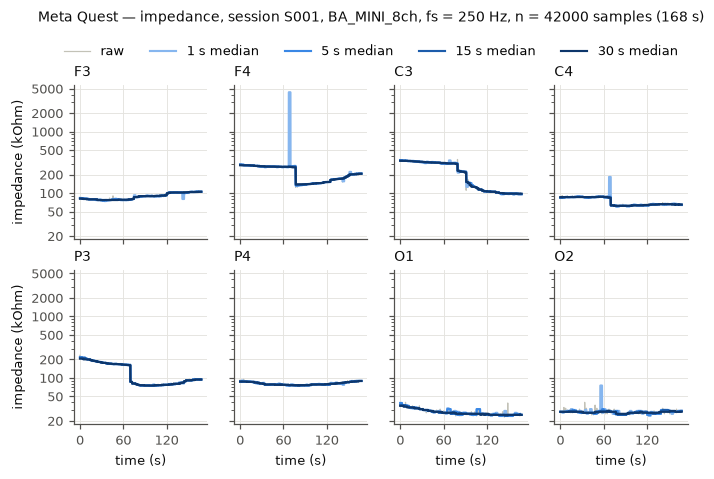

In [6]:
for (task, session, device), recs in groups.items():
    for r in recs:
        vr = r["meta"]["vr_set"]
        fig, axes = channel_grid(len(r["eeg"]))
        for ax, ch in zip(axes, r["eeg"]):
            ax.plot(r["time"], r["z"][ch], color=RAW_COLOR, lw=0.8, label="raw")
            for w, col in zip(WINDOWS_S, WINDOW_RAMP):
                ax.plot(r["time"], smoothed[(task, session, device, vr, w)][ch], color=col, lw=1.4,
                        label=f"{w} s median")
            ax.set_title(ch, loc="left", color=INK)
            log_axis(ax)
        label_axes(axes, f"impedance ({r['unit']})")
        h, l = axes[0].get_legend_handles_labels()
        fig.legend(h, l, loc="upper center", ncol=len(l), bbox_to_anchor=(0.5, 1.0))
        fig.suptitle(f"{COND_LABELS.get(vr, vr)} — {task}, session {session}, {device}, "
                     f"fs = {r['fs']:g} Hz, n = {len(r['time'])} samples ({len(r['time'])/r['fs']:.0f} s)",
                     y=1.05, fontsize=9, color=INK)
        save(fig, f"impedance_windows_{stem(task, session, device, vr)}")
        plt.show()

### Figure B — VR conditions compared (reference window)

All VR conditions on a common time axis (time from recording start),
smoothed with the reference window.

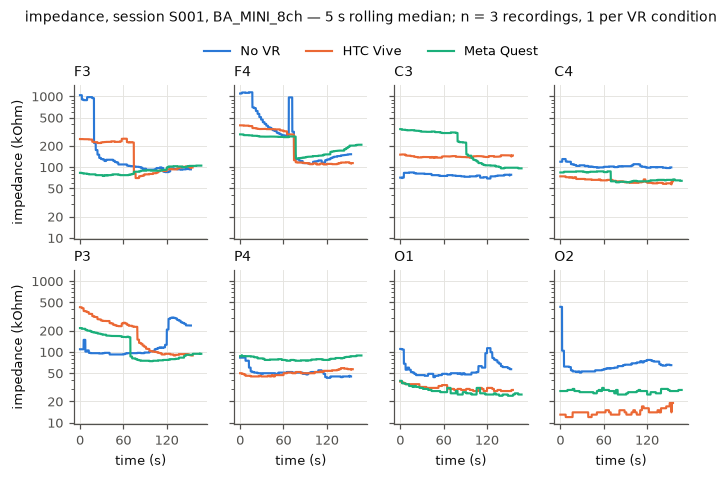

In [7]:
for (task, session, device), recs in groups.items():
    eeg = recs[0]["eeg"]
    fig, axes = channel_grid(len(eeg))
    for ax, ch in zip(axes, eeg):
        for r in recs:
            vr = r["meta"]["vr_set"]
            ax.plot(r["time"], smoothed[(task, session, device, vr, REFERENCE_WINDOW_S)][ch],
                    color=cond_color(vr), label=COND_LABELS.get(vr, vr))
        ax.set_title(ch, loc="left", color=INK)
        log_axis(ax)
    label_axes(axes, f"impedance ({recs[0]['unit']})")
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc="upper center", ncol=len(l), bbox_to_anchor=(0.5, 1.0))
    fig.suptitle(f"{task}, session {session}, {device} — {REFERENCE_WINDOW_S} s rolling median; "
                 f"n = {len(recs)} recordings, 1 per VR condition", y=1.05, fontsize=9, color=INK)
    save(fig, f"impedance_conditions_{stem(task, session, device)}")
    plt.show()

## Summary statistics

Per recording and channel (all samples, no exclusions):

* **median** and **IQR** of the raw impedance;
* **initial** / **final** impedance — median of the first / last `EDGE_S` seconds;
* **change** — final relative to initial, in %;
* **settling time** — the last time the reference-window median lies outside
  ±max(`SETTLE_TOL`·final, `SETTLE_ABS`) of the final impedance (0 s if it never leaves the band; the
  first `w`/2 s with no smoothed value are not counted);
* **time above 3× median** — share of samples above 3 × the channel's recording median
  (captures both spikes and prolonged high-impedance periods);
* **drift slope** — Theil–Sen slope (kΩ/min) of the medians of consecutive,
  non-overlapping windows of length *w*, computed for every *w* in `WINDOWS_S`
  to show how the drift estimate depends on the window.

Theil–Sen is used because it is robust to the spikes. These are descriptive
quantities for single recordings; no p-values are attached to them because
consecutive samples are strongly autocorrelated.

In [8]:
def settling_time(trace: np.ndarray, t: np.ndarray, final: float, tol: float, abs_tol: float) -> float:
    ok = np.isfinite(trace)
    outside = ok & (np.abs(trace - final) > max(tol * final, abs_tol))
    if not outside.any():
        return 0.0
    return float(t[np.flatnonzero(outside)[-1]])

def window_medians(z: pd.Series, fs: float, w: float):
    n = int(round(w * fs))
    k = len(z) // n
    if k < 3:
        return None, None
    block = z.to_numpy()[: k * n].reshape(k, n)
    return (np.arange(k) + 0.5) * w / 60.0, np.median(block, axis=1)  # minutes, kOhm

rows, slope_rows = [], []
for (task, session, device), recs in groups.items():
    for r in recs:
        vr, fs, n_edge = r["meta"]["vr_set"], r["fs"], int(EDGE_S * r["fs"])
        ref = smoothed[(task, session, device, vr, REFERENCE_WINDOW_S)]
        for ch in r["eeg"]:
            z = r["z"][ch]
            init, final = z.iloc[:n_edge].median(), z.iloc[-n_edge:].median()
            q1, q3 = z.quantile([0.25, 0.75])
            rows.append(dict(task=task, session=session, device=device, vr_set=vr, channel=ch,
                             median=z.median(), q1=q1, q3=q3, initial=init, final=final,
                             change_pct=100 * (final - init) / init,
                             settling_s=settling_time(ref[ch].to_numpy(), r["time"], final, SETTLE_TOL, SETTLE_ABS),
                             above3x_pct=100 * (z > 3 * z.median()).mean(), max=z.max()))
            for w in WINDOWS_S:
                tm, med = window_medians(z, fs, w)
                if tm is None:
                    continue
                slope, _, lo, hi = stats.theilslopes(med, tm, alpha=0.95)
                slope_rows.append(dict(task=task, session=session, device=device, vr_set=vr, channel=ch,
                                       window_s=w, n_windows=len(med), slope=slope, slope_lo=lo, slope_hi=hi))

summary = pd.DataFrame(rows)
slopes = pd.DataFrame(slope_rows)
summary.round(1)

,task,session,device,vr_set,channel,median,q1,q3,initial,final,change_pct,settling_s,above3x_pct,max
0,impedance,S001,BA_MINI_8ch,NoVR,F3,103.0,94.0,127.0,902.0,93.0,-89.7,69.7,12.6,1070.0
1,impedance,S001,BA_MINI_8ch,NoVR,F4,152.0,128.0,431.0,1119.0,149.0,-86.7,127.3,23.5,1784.0
2,impedance,S001,BA_MINI_8ch,NoVR,C3,76.0,74.0,78.8,81.0,78.0,-3.7,0.0,0.0,185.0
3,impedance,S001,BA_MINI_8ch,NoVR,C4,102.0,100.0,106.0,120.0,98.0,-18.3,110.5,0.0,378.0
4,impedance,S001,BA_MINI_8ch,NoVR,P3,98.0,95.0,126.0,109.0,237.0,117.4,141.7,6.3,339.0
5,impedance,S001,BA_MINI_8ch,NoVR,P4,51.0,48.0,52.0,83.0,45.0,-45.8,14.5,0.0,292.0
6,impedance,S001,BA_MINI_8ch,NoVR,O1,51.0,48.0,61.0,68.0,60.0,-11.8,136.9,0.0,209.0
7,impedance,S001,BA_MINI_8ch,NoVR,O2,63.0,55.0,69.0,64.0,65.0,1.6,127.3,1.6,433.0
8,impedance,S001,BA_MINI_8ch,HTC,F3,102.0,87.0,227.0,248.0,101.0,-59.3,120.1,0.0,8288.0
9,impedance,S001,BA_MINI_8ch,HTC,F4,119.0,113.0,344.0,385.0,115.0,-70.1,74.5,10.8,399.0


### Window sensitivity

Two views of what the window length does:

* **residual variation** — mean absolute difference between the raw signal
  and its rolling median (kΩ), i.e. how much short-term variation (spikes,
  brief excursions) the window removes; summarised per recording as the median
  over channels. The mean is used because the signal is step-wise: the raw
  value equals its rolling median most of the time, so a median residual is 0
  for every window and carries no information;
* **drift slope vs. window** — median over channels of the Theil–Sen slope.

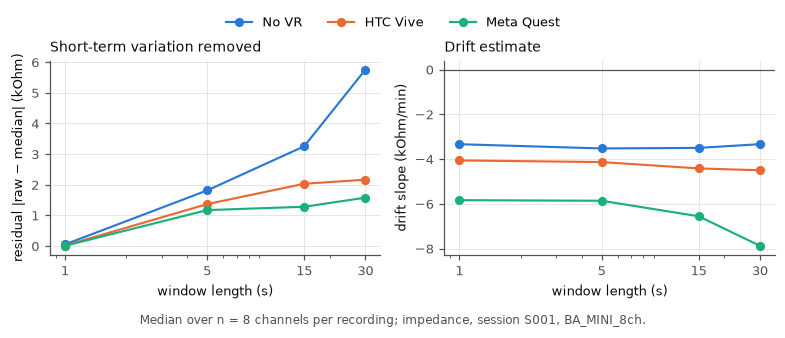

,task,session,device,vr_set,window_s,resid_median,slope_median,slope_abs_max,n_windows
0,impedance,S001,BA_MINI_8ch,HTC,1,0.01,-4.06,121.74,156
1,impedance,S001,BA_MINI_8ch,HTC,5,1.37,-4.13,124.00,31
2,impedance,S001,BA_MINI_8ch,HTC,15,2.03,-4.42,140.00,10
3,impedance,S001,BA_MINI_8ch,HTC,30,2.16,-4.50,144.08,5
4,impedance,S001,BA_MINI_8ch,MetaQuest,1,0.01,-5.84,106.67,168
5,impedance,S001,BA_MINI_8ch,MetaQuest,5,1.17,-5.86,108.23,33
6,impedance,S001,BA_MINI_8ch,MetaQuest,15,1.28,-6.56,114.00,11
7,impedance,S001,BA_MINI_8ch,MetaQuest,30,1.58,-7.88,125.92,5
8,impedance,S001,BA_MINI_8ch,NoVR,1,0.05,-3.34,230.46,153
9,impedance,S001,BA_MINI_8ch,NoVR,5,1.81,-3.52,249.39,30


In [9]:
resid_rows = []
for (task, session, device), recs in groups.items():
    for r in recs:
        vr = r["meta"]["vr_set"]
        for w in WINDOWS_S:
            sm = smoothed[(task, session, device, vr, w)]
            per_ch = (r["z"] - sm).abs().mean()
            for ch, v in per_ch.items():
                resid_rows.append(dict(task=task, session=session, device=device, vr_set=vr,
                                       channel=ch, window_s=w, resid=v))
resid = pd.DataFrame(resid_rows)

window_tab = (resid.groupby(["task", "session", "device", "vr_set", "window_s"])["resid"].median()
              .to_frame("resid_median")
              .join(slopes.groupby(["task", "session", "device", "vr_set", "window_s"])
                    .agg(slope_median=("slope", "median"),
                         slope_abs_max=("slope", lambda s: s.abs().max()),
                         n_windows=("n_windows", "first")))
              .reset_index())

for (task, session, device), recs in groups.items():
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.2, 2.6))
    for r in recs:
        vr = r["meta"]["vr_set"]
        sel = window_tab[(window_tab.task == task) & (window_tab.session == session)
                         & (window_tab.device == device) & (window_tab.vr_set == vr)]
        kw = dict(color=cond_color(vr), marker="o", ms=5, label=COND_LABELS.get(vr, vr))
        a1.plot(sel.window_s, sel.resid_median, **kw)
        a2.plot(sel.window_s, sel.slope_median, **kw)
    for ax in (a1, a2):
        ax.set_xscale("log"); ax.set_xticks(WINDOWS_S); ax.set_xticklabels([str(w) for w in WINDOWS_S])
        ax.set_xlabel("window length (s)")
    a2.axhline(0, color=INK2, lw=0.8)
    a1.set_ylabel(f"residual |raw − median| ({recs[0]['unit']})")
    a2.set_ylabel(f"drift slope ({recs[0]['unit']}/min)")
    a1.set_title("Short-term variation removed", loc="left", color=INK)
    a2.set_title("Drift estimate", loc="left", color=INK)
    n_ch = len(recs[0]["eeg"])
    h, l = a1.get_legend_handles_labels()
    fig.legend(h, l, loc="upper center", ncol=len(l), bbox_to_anchor=(0.5, 1.08))
    fig.text(0.5, -0.04, f"Median over n = {n_ch} channels per recording; {task}, session {session}, {device}.",
             ha="center", color=INK2, fontsize=8)
    fig.tight_layout()
    save(fig, f"impedance_window_sensitivity_{stem(task, session, device)}")
    plt.show()
window_tab.round(2)

## Exploratory comparison of VR conditions

With one recording per condition the only replication available is across
electrodes. As an **exploratory** check, per-channel median impedances are
compared across conditions with a Friedman test (channels as blocks) and
pairwise Wilcoxon signed-rank tests against the no-VR condition (exact
two-sided p-values, no multiplicity correction). Channels of one headset are
not independent subjects, so these p-values describe this recording session
only and must not be generalised to a population.

In [10]:
test_rows = []
for (task, session, device), recs in groups.items():
    sub = summary[(summary.task == task) & (summary.session == session) & (summary.device == device)]
    wide = sub.pivot(index="channel", columns="vr_set", values="median")
    conds = [r["meta"]["vr_set"] for r in recs]
    if len(conds) >= 3:
        f = stats.friedmanchisquare(*[wide[c] for c in conds])
        test_rows.append(dict(task=task, session=session, device=device, test="Friedman",
                              comparison=" vs ".join(conds), n=len(wide), statistic=f.statistic, p=f.pvalue))
    base = "NoVR" if "NoVR" in conds else conds[0]
    for c in conds:
        if c == base:
            continue
        wres = stats.wilcoxon(wide[c], wide[base], method="exact")
        test_rows.append(dict(task=task, session=session, device=device, test="Wilcoxon",
                              comparison=f"{c} vs {base}", n=len(wide), statistic=wres.statistic, p=wres.pvalue,
                              median_diff=float((wide[c] - wide[base]).median())))
tests = pd.DataFrame(test_rows)
tests.round(4)

,task,session,device,test,comparison,n,statistic,p,median_diff
0,impedance,S001,BA_MINI_8ch,Friedman,NoVR vs HTC vs MetaQuest,8,2.25,0.3247,NaN
1,impedance,S001,BA_MINI_8ch,Wilcoxon,HTC vs NoVR,8,15.00,0.7422,-10.5
2,impedance,S001,BA_MINI_8ch,Wilcoxon,MetaQuest vs NoVR,8,17.00,0.9453,-11.0


## Export: tables, TeX macros, provenance

Tables are written as CSV (full precision) and LaTeX (rounded, `booktabs`).
`impedance_results_<group>.tex` defines macros holding every number quoted in
the article text, so the article and the notebook cannot disagree.

In [11]:
def tex_escape(s):
    return str(s).replace("_", r"\_").replace("%", r"\%")

def signed(v, fmt):
    # proper minus sign in text mode
    txt = format(v, fmt)
    return rf"\ensuremath{{{txt}}}" if txt[0] in "+-" else txt

def macro_name(*parts):
    digits = {"0": "zero", "1": "one", "2": "two", "3": "three", "4": "four", "5": "five",
              "6": "six", "7": "seven", "8": "eight", "9": "nine"}
    s = "".join(str(p) for p in parts)
    s = "".join(digits.get(ch, ch) for ch in s)
    return "imp" + re.sub(r"[^A-Za-z]", "", s)

for (task, session, device), recs in groups.items():
    g = stem(task, session, device)
    sel = lambda df: df[(df.task == task) & (df.session == session) & (df.device == device)]
    s, ws, sl, ts = sel(summary), sel(window_tab), sel(slopes), sel(tests) if len(tests) else tests
    conds = [r["meta"]["vr_set"] for r in recs]
    unit = recs[0]["unit"]
    unit_tex = r"k$\Omega$" if unit == "kOhm" else tex_escape(unit)

    for name, df in [("summary", s), ("window_sensitivity", ws), ("drift_slopes", sl), ("condition_tests", ts)]:
        p = TAB_DIR / f"impedance_{name}_{g}.csv"
        df.to_csv(p, index=False); generated.append(p)

    # Table 1: per channel x condition: median [IQR], initial -> final, settling
    lines = [r"\begin{tabular}{l" + "rrr" * len(conds) + "}", r"\toprule",
             " & " + " & ".join(rf"\multicolumn{{3}}{{c}}{{{COND_LABELS.get(c, c)}}}" for c in conds) + r" \\",
             "".join(rf"\cmidrule(lr){{{2 + 3*i}-{4 + 3*i}}}" for i in range(len(conds))),
             "Ch. & " + " & ".join(["median [IQR]", "init.\\,$\\to$\\,final", "settle (s)"] * len(conds)) + r" \\",
             r"\midrule"]
    for ch in recs[0]["eeg"]:
        cells = []
        for c in conds:
            r_ = s[(s.vr_set == c) & (s.channel == ch)].iloc[0]
            cells += [f"{r_['median']:.0f} [{r_.q1:.0f}--{r_.q3:.0f}]",
                      f"{r_.initial:.0f}\\,$\\to$\\,{r_.final:.0f}", f"{r_.settling_s:.0f}"]
        lines.append(f"{ch} & " + " & ".join(cells) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}"]
    p = TAB_DIR / f"impedance_summary_{g}.tex"; p.write_text("\n".join(lines) + "\n"); generated.append(p)

    # Table 2: window sensitivity
    lines = [r"\begin{tabular}{r" + "rr" * len(conds) + "}", r"\toprule",
             " & " + " & ".join(rf"\multicolumn{{2}}{{c}}{{{COND_LABELS.get(c, c)}}}" for c in conds) + r" \\",
             "".join(rf"\cmidrule(lr){{{2 + 2*i}-{3 + 2*i}}}" for i in range(len(conds))),
             "Window (s) & " + " & ".join([f"resid. ({unit_tex})", f"slope ({unit_tex}/min)"] * len(conds)) + r" \\",
             r"\midrule"]
    for w in WINDOWS_S:
        cells = []
        for c in conds:
            r_ = ws[(ws.vr_set == c) & (ws.window_s == w)].iloc[0]
            cells += [f"{r_.resid_median:.1f}", signed(r_.slope_median, "+.1f")]
        lines.append(f"{w} & " + " & ".join(cells) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}"]
    p = TAB_DIR / f"impedance_window_sensitivity_{g}.tex"; p.write_text("\n".join(lines) + "\n"); generated.append(p)

    # Macros used by the article text
    M = {}
    M["impNChannels"] = len(recs[0]["eeg"])
    M["impFs"] = f"{recs[0]['fs']:g}"
    M["impDevice"] = tex_escape(device)
    M["impSession"] = tex_escape(session)
    M["impUnit"] = r"k$\Omega$" if unit == "kOhm" else tex_escape(unit)
    M["impWindows"] = ", ".join(str(w) for w in WINDOWS_S)
    M["impRefWindow"] = REFERENCE_WINDOW_S
    M["impEdge"] = EDGE_S
    M["impTolPct"] = f"{SETTLE_TOL*100:.0f}"
    M["impTolFrac"] = f"{SETTLE_TOL:g}"
    M["impTolAbs"] = f"{SETTLE_ABS:g}"
    M["impRunDate"] = RUN_DATE
    M["impSubject"] = tex_escape(recs[0]["meta"]["subject"])
    for r in recs:
        c = r["meta"]["vr_set"]; sc = s[s.vr_set == c]
        M[macro_name("Dur", c)] = f"{len(r['time'])/r['fs']:.0f}"
        M[macro_name("NSamples", c)] = f"{len(r['time'])}"
        M[macro_name("MedMed", c)] = f"{sc['median'].median():.0f}"
        M[macro_name("MedMin", c)] = f"{sc['median'].min():.0f}"
        M[macro_name("MedMax", c)] = f"{sc['median'].max():.0f}"
        M[macro_name("MedMinCh", c)] = sc.loc[sc['median'].idxmin(), "channel"]
        M[macro_name("MedMaxCh", c)] = sc.loc[sc['median'].idxmax(), "channel"]
        M[macro_name("InitMed", c)] = f"{sc.initial.median():.0f}"
        M[macro_name("FinalMed", c)] = f"{sc.final.median():.0f}"
        M[macro_name("NDecrease", c)] = int((sc.change_pct < -SETTLE_TOL*100).sum())
        M[macro_name("NIncrease", c)] = int((sc.change_pct > SETTLE_TOL*100).sum())
        M[macro_name("SettleMed", c)] = f"{sc.settling_s.median():.0f}"
        M[macro_name("SettleMax", c)] = f"{sc.settling_s.max():.0f}"
        M[macro_name("SettleMaxCh", c)] = sc.loc[sc.settling_s.idxmax(), "channel"]
        M[macro_name("Max", c)] = f"{sc['max'].max():.0f}"
        M[macro_name("MaxCh", c)] = sc.loc[sc['max'].idxmax(), "channel"]
        M[macro_name("AboveMaxPct", c)] = f"{sc.above3x_pct.max():.1f}"
        M[macro_name("AboveMaxCh", c)] = sc.loc[sc.above3x_pct.idxmax(), "channel"]
        drop = (sc.initial - sc.final).idxmax()
        M[macro_name("DropCh", c)] = sc.loc[drop, "channel"]
        M[macro_name("DropInit", c)] = f"{sc.loc[drop, 'initial']:.0f}"
        M[macro_name("DropFinal", c)] = f"{sc.loc[drop, 'final']:.0f}"
        M[macro_name("DropSettle", c)] = f"{sc.loc[drop, 'settling_s']:.0f}"
        M[macro_name("NSettledSixty", c)] = int((sc.settling_s <= 60).sum())
        wc = ws[ws.vr_set == c].set_index("window_s")
        for w in WINDOWS_S:
            M[macro_name("Resid", c, "W", w)] = f"{wc.loc[w, 'resid_median']:.1f}"
            M[macro_name("SmoothMax", c, "W", w)] = f"{smoothed[(task, session, device, c, w)].max().max():.0f}"
            M[macro_name("Slope", c, "W", w)] = signed(wc.loc[w, 'slope_median'], "+.1f")
            M[macro_name("SlopeAbsMax", c, "W", w)] = f"{wc.loc[w, 'slope_abs_max']:.1f}"
    for _, t in ts.iterrows():
        key = "Friedman" if t.test == "Friedman" else "Wilcoxon" + t.comparison.split(" vs ")[0]
        M[macro_name(key, "Stat")] = f"{t.statistic:.2f}" if t.test == "Friedman" else f"{t.statistic:.0f}"
        M[macro_name(key, "P")] = f"{t.p:.3f}"
        if t.test == "Wilcoxon":
            M[macro_name(key, "Diff")] = signed(t.median_diff, "+.0f")
    body = "\n".join(rf"\newcommand{{\{k}}}{{{v}}}" for k, v in M.items())
    p = OUTPUT_DIR / f"impedance_results_{g}.tex"
    p.write_text(f"% Generated by {NOTEBOOK} on {RUN_DATE}. Do not edit by hand.\n"
                 f"% Group: {g}; sources: " + ", ".join(r["path"].name for r in recs) + "\n" + body + "\n")
    generated.append(p)

    prov = dict(notebook=NOTEBOOK, processing_date=RUN_DATE, group=g,
                parameters=dict(WINDOWS_S=WINDOWS_S, REFERENCE_WINDOW_S=REFERENCE_WINDOW_S,
                                EDGE_S=EDGE_S, SETTLE_TOL=SETTLE_TOL),
                sources=[dict(file=r["path"].name, source_sha256=r["meta"]["source_sha256"],
                              vr_set=r["meta"]["vr_set"], n_eeg_channels=len(r["eeg"])) for r in recs])
    p = OUTPUT_DIR / f"impedance_provenance_{g}.json"
    p.write_text(json.dumps(prov, indent=2) + "\n"); generated.append(p)

print("Generated files:")
for p in sorted(set(generated)):
    print("  ", p.relative_to(PROJECT_ROOT))

Generated files:
   outputs/impedance/figures/impedance_conditions_impedance-S001-BA_MINI_8ch.pdf
   outputs/impedance/figures/impedance_conditions_impedance-S001-BA_MINI_8ch.png
   outputs/impedance/figures/impedance_window_sensitivity_impedance-S001-BA_MINI_8ch.pdf
   outputs/impedance/figures/impedance_window_sensitivity_impedance-S001-BA_MINI_8ch.png
   outputs/impedance/figures/impedance_windows_impedance-S001-HTC-BA_MINI_8ch.pdf
   outputs/impedance/figures/impedance_windows_impedance-S001-HTC-BA_MINI_8ch.png
   outputs/impedance/figures/impedance_windows_impedance-S001-MetaQuest-BA_MINI_8ch.pdf
   outputs/impedance/figures/impedance_windows_impedance-S001-MetaQuest-BA_MINI_8ch.png
   outputs/impedance/figures/impedance_windows_impedance-S001-NoVR-BA_MINI_8ch.pdf
   outputs/impedance/figures/impedance_windows_impedance-S001-NoVR-BA_MINI_8ch.png
   outputs/impedance/impedance_provenance_impedance-S001-BA_MINI_8ch.json
   outputs/impedance/impedance_results_impedance-S001-BA_MINI_8

## Limitations

* One subject, one session, one recording per VR condition; conditions were
  recorded sequentially, so condition is confounded with recording order and
  with time since electrode placement.
* Impedance is the value reported by the BrainAccess firmware; its measurement
  method and update rate are not documented in the data.
* The rolling median truncates at recording edges (first/last *w*/2 s missing).
* Settling time depends on `SETTLE_TOL`, `SETTLE_ABS` and `REFERENCE_WINDOW_S`; the final
  impedance is defined from the last `EDGE_S` seconds only.